In [92]:
# imports : 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

In [93]:
%run ./2_transformatioNpreparation.ipynb

In [94]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(),

    "Random Forest": RandomForestClassifier(n_jobs=-1)
}
results = {}
def train(x_train , y_train, models): 
    
    for model_name , model in models.items(): 
        
        pipeline = Pipeline(
            [
                (
                    'preprocessor', preprocessor 
                ), 
                (
                    'model' , model
                )
            ]
        )
        pipeline.fit(x_train , y_train) 
        y_pred = pipeline.predict(x_test)
        y_proba = pipeline.predict_proba(x_test)
        accuracy = accuracy_score(y_test , y_pred)
        precision = precision_score(y_test, y_pred, average="macro")
        recall = recall_score(y_test , y_pred, average="macro")
        f1_Score = f1_score(y_test , y_pred, average="macro")
        
        results[model_name] = {
            "model_pipeline" : pipeline,
            "proba" : y_proba,
            "accuracy" : accuracy , 
            "precision" : precision,
            "recall" : recall , 
            "f1_score" : f1_Score ,
            "y_pred" :  y_pred
        }
        
        
train(x_train , y_train , models)     
    

0.7575

In [95]:
results

{'Logistic Regression': {'model_pipeline': Pipeline(steps=[('preprocessor',
                   ColumnTransformer(remainder='passthrough',
                                     transformers=[('num_features',
                                                    Pipeline(steps=[('imputer',
                                                                     SimpleImputer(strategy='median')),
                                                                    ('scaler',
                                                                     StandardScaler())]),
                                                    ['Age', 'Year_of_Study',
                                                     'Sleep_Hours',
                                                     'Study_Hours_Per_Week',
                                                     'GPA', 'Social_Media_Hours',
                                                     'Screen_Time_Hours',
                                                     'Financial

In [ ]:
# calculate the roc_auc socre : 


roc_auc = roc_auc_score(y_test , results['Logistic Regression']['proba'], multi_class="ovr")
roc_auc

0.9140359643405077

In [97]:
# prepare real labels . 
classes = results['Logistic Regression']['model_pipeline'].classes_
classes

y_test_bin = label_binarize(y_test , classes=classes)

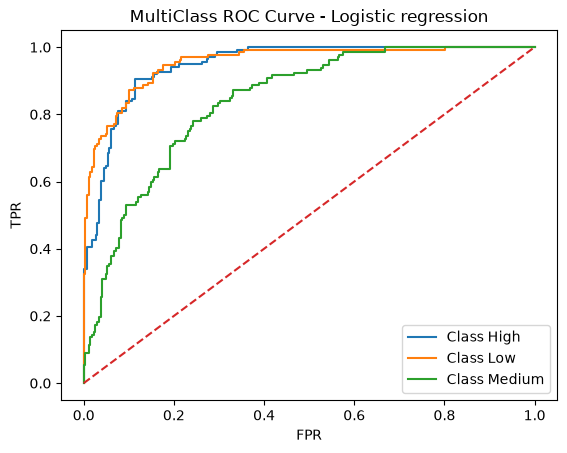

In [98]:

for i , class_name in enumerate(classes) : 
    fpr , tpr , thresholds = roc_curve(
        y_test_bin[:, i], 
        results['Logistic Regression']["proba"][:, i]
    )
    plt.plot(fpr, tpr , label=f"Class {class_name}")

plt.plot([0,1] , [0,1], linestyle="--")


plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("MultiClass ROC Curve - Logistic regression")

plt.legend()
plt.show()


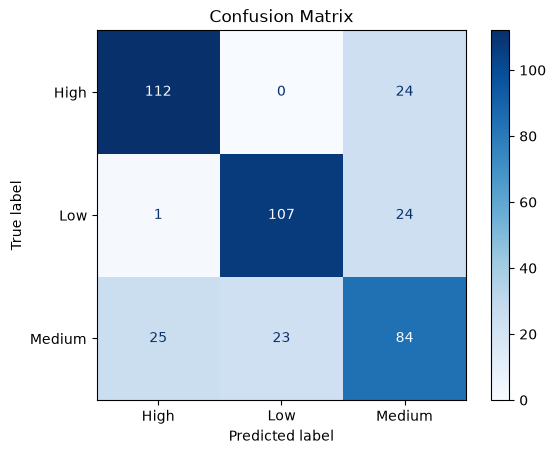

In [99]:
# confusion matrix :
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test , results['Logistic Regression']["y_pred"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=classes)

disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()
